# Label prediction: results

Can the rules predict a patient's label (steroid response, survival, ...)? This notebook only reads the runs saved by `run_predictions.py`; nothing is rerun here.

In [1]:
import prediction_search as ps
import prediction_vis as pv
import run_predictions as rp

runs = ps.saved_runs(rp.PREDICTIONS, rp.UNITS)
best = pv.best_per_prediction(runs)

## 1. Best result per question

- **Small pale dots**: every rule run (every rule set, feature, filter and model), spread up and down a little so they don't hide each other.
- **Hollow blue dot**: the typical rule run (median).
- **Big blue dot**: the best rule run.
- **Teal, orange, brown**: the best score with no rules - cell composition, pathological score, clinical score.
- Rows are sorted by how far the best rule run beats the best of these, per patient.

The best of ~200 runs always looks better than it is. Diagnosis is a control with no reason to be predictable, so its best dot shows how high luck alone reaches.

saved c:\Users\Owner\Documents\script-rule-mining\result_summary\label_prediction\output\best_per_prediction.pdf


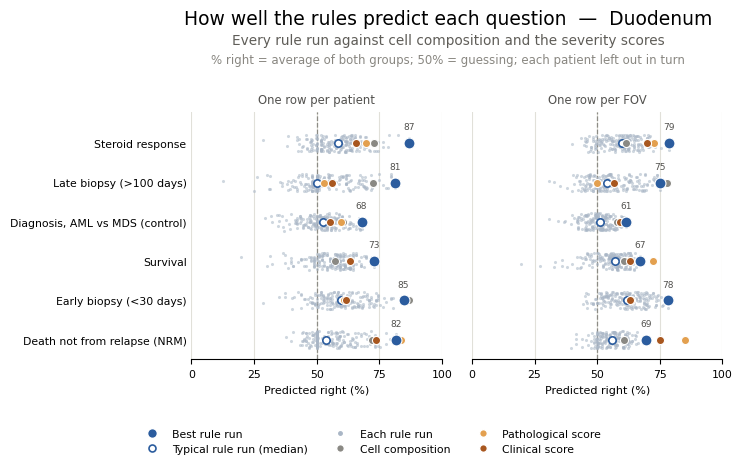

In [2]:
pv.plot_best(runs, save="best_per_prediction.pdf")

The setting behind each best rule run:

In [3]:
best[["prediction", "unit", "best_rules", "best_reference", "best_setting",
      "best_model", "best_auc"]].round(1)

,prediction,unit,best_rules,best_reference,best_setting,best_model,best_auc
0,cortico_response,patient,86.9,72.9,"Attraction + avoidance, all sizes · mean lif...",Lasso logistic regression,95.1
1,cortico_response,FOV,78.6,72.8,"Attraction, pairwise · share of FOVs · in ...",Ridge logistic regression,80.6
2,cause_of_death_nrm_muscle,patient,81.5,83.8,"Attraction, all sizes · share of FOVs · in...",Ridge logistic regression,76.9
3,cause_of_death_nrm_muscle,FOV,69.4,85.2,"Attraction + avoidance, all sizes · share of...",Lasso logistic regression,84.9
4,survival_at_follow_up,patient,72.9,72.9,"Attraction + avoidance, pairwise · mean lift...",Azulay: 2 PCA + linear SVM,69.3
5,survival_at_follow_up,FOV,67.0,72.2,"Attraction + avoidance, pairwise · mean conv...",Ridge logistic regression,67.7
6,days_after_transplant_grouped_under30,patient,84.7,86.8,"Attraction, all sizes · share of FOVs · in...",Ridge logistic regression,85.9
7,days_after_transplant_grouped_under30,FOV,78.3,79.1,"Attraction + avoidance, pairwise · share of ...",Lasso logistic regression,82.9
8,days_after_transplant_grouped_over100,patient,81.2,72.6,"Attraction + avoidance, pairwise · mean lift...",Lasso logistic regression,78.4
9,days_after_transplant_grouped_over100,FOV,75.1,77.7,"Attraction + avoidance, pairwise · mean conv...",Lasso logistic regression,67.1
